# 12 — Antes de postar: qual a chance (%) de cair no top 5%?

**Pergunta:** dado um post planejado, qual a probabilidade de ele ficar entre os **5% melhores do seu formato** (vídeo, imagem, texto ou misto) em **views**, **likes** e **comentários**?

**Modelos comparados (um por métrica × formato):**
| Modelo | Ideia |
|---|---|
| taxa base | 5% para todo post (referência) |
| segmento | taxa histórica de plataforma × categoria × idioma, encolhida para a base quando há poucos posts (Bayes empírico) |
| regressão logística | todas as variáveis pré-postagem |
| LightGBM calibrado | árvores com probabilidade calibrada |

**Validação:** treino no passado e teste nos posts mais recentes.
- **AUC:** o modelo ordena quem bomba? (0,5 = acaso)
- **Brier:** a % prometida bate com a realidade? (menor = melhor)
- **Adoção:** só se o modelo vence a base no Brier **e** a AUC > 0,5 sobrevive à correção para os 36 testes.

In [1]:
# Setup: make solution/src importable and load the posts with derived features.
import sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "solution" / "src").exists())
sys.path.insert(0, str(ROOT / "solution" / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from social_insights import data, top_performers as tp, clustering as cl, drivers as dr, audience as au, nlp, validation as va, plots

plots.apply_style()
pd.set_option("display.float_format", "{:.4f}".format)
df = data.load_posts(ROOT)
print(f"{len(df):,} posts")

from social_insights import hit_probability as hp
from social_insights.views_forecast import add_creator_history
predictor = hp.HitPredictor.train(df)
ev = predictor.evaluation
display(Markdown(f"Modelos adotados: **{sum(v != 'taxa base' for v in predictor.chosen.values())} de {len(predictor.chosen)}** combinações (métrica × formato)"))
ev[["métrica", "formato", "modelo", "posts teste", "hits teste", "AUC", "p (AUC > 0,5)", "q (AUC)", "ganho Brier vs. base (%)",
    "taxa real no top 10% previsto (%)", "adotável"]].round(4)

52,214 posts


Modelos adotados: **0 de 12** combinações (métrica × formato)

,métrica,formato,modelo,posts teste,hits teste,AUC,"p (AUC > 0,5)",q (AUC),ganho Brier vs. base (%),taxa real no top 10% previsto (%),adotável
0,views,image,taxa base,2061,109,0.5000,1.0000,NaN,0.0000,5.0109,False
1,views,image,segmento (plataforma × categoria × idioma),2061,109,0.4373,0.9863,0.9931,-0.3481,4.4944,False
2,views,image,regressão logística,2061,109,0.5012,0.4832,0.9535,-0.5462,4.8309,False
3,views,image,LightGBM calibrado,2061,109,0.5102,0.3595,0.8089,0.0098,5.7971,False
4,views,mixed,taxa base,1043,56,0.5000,1.0000,NaN,0.0000,4.9880,False
5,views,mixed,segmento (plataforma × categoria × idioma),1043,56,0.4691,0.7824,0.9833,-0.1786,4.2017,False
6,views,mixed,regressão logística,1043,56,0.4729,0.7528,0.9833,-0.9909,4.7619,False
7,views,mixed,LightGBM calibrado,1043,56,0.5174,0.3309,0.8089,0.0008,3.8095,False
8,views,text,taxa base,1040,52,0.5000,1.0000,NaN,0.0000,5.0986,False
9,views,text,segmento (plataforma × categoria × idioma),1040,52,0.4213,0.9723,0.9931,-0.4782,1.8868,False


## 1. Quem ordena melhor os posts que bombam? (AUC no teste)

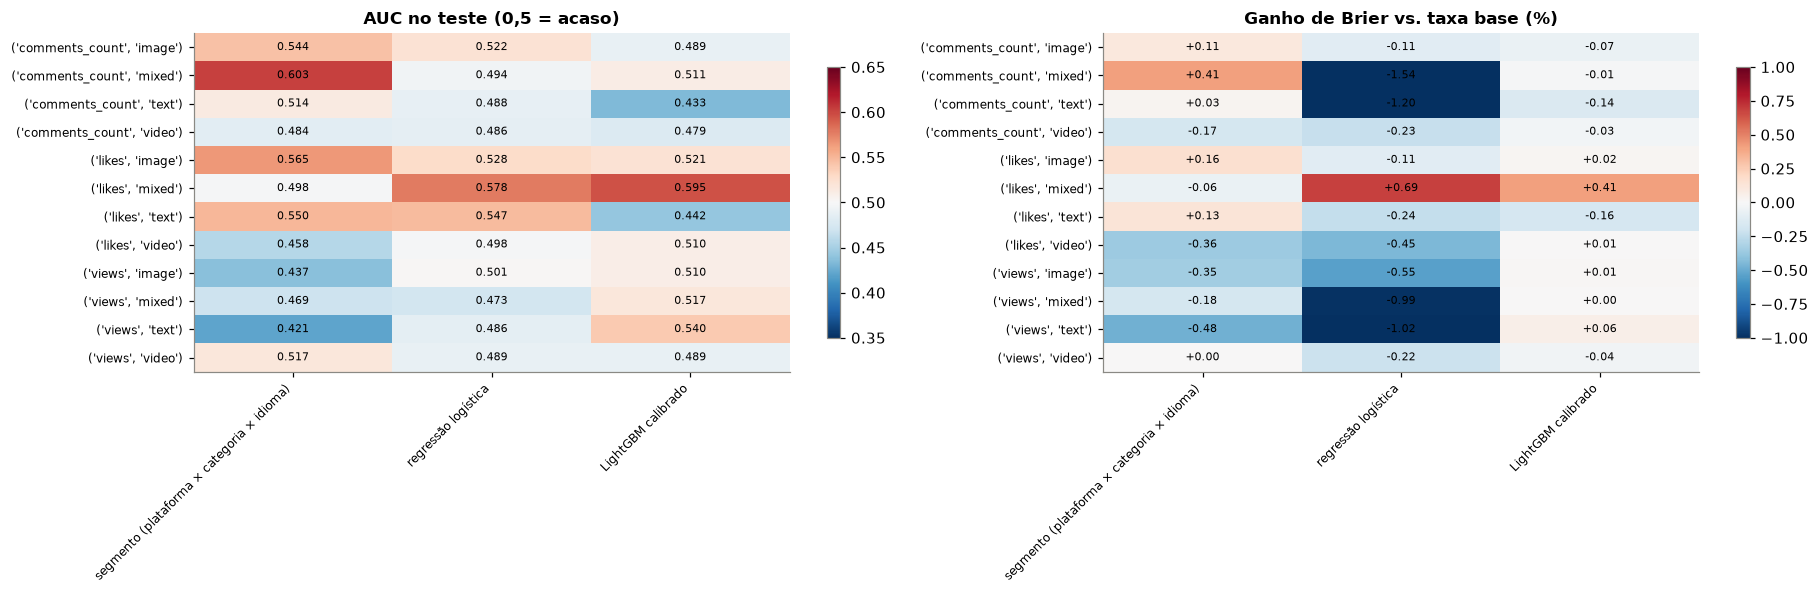

In [2]:
auc = ev.pivot_table(index=["métrica", "formato"], columns="modelo", values="AUC")[hp.CANDIDATES[1:]]
fig, axes = plt.subplots(1, 2, figsize=(17, 5.5))
plots.heatmap(axes[0], auc, "AUC no teste (0,5 = acaso)", vmin=0.35, vmax=0.65, fmt="{:.3f}")
gain = ev.pivot_table(index=["métrica", "formato"], columns="modelo", values="ganho Brier vs. base (%)")[hp.CANDIDATES[1:]]
plots.heatmap(axes[1], gain, "Ganho de Brier vs. taxa base (%)", vmin=-1, vmax=1, fmt="{:+.2f}")
fig.tight_layout(); plt.show()

**Leitura:** as AUCs ficam entre ~0,42 e ~0,60, ao redor do acaso. Os ganhos de Brier são de no máximo 0,7%.
Os melhores sinais aparecem em **likes e comentários de posts mistos/imagem** (AUC 0,56–0,60, p < 0,05 isolado), formatos com poucos posts no teste. Com 36 testes, nenhum sobrevive à correção (q ≥ 0,1).
Por isso o previsor usa a **taxa base** como chance oficial e mostra o **sinal do segmento** como pista.

## 2. Calibração: quando o modelo diz X%, acontece X%?

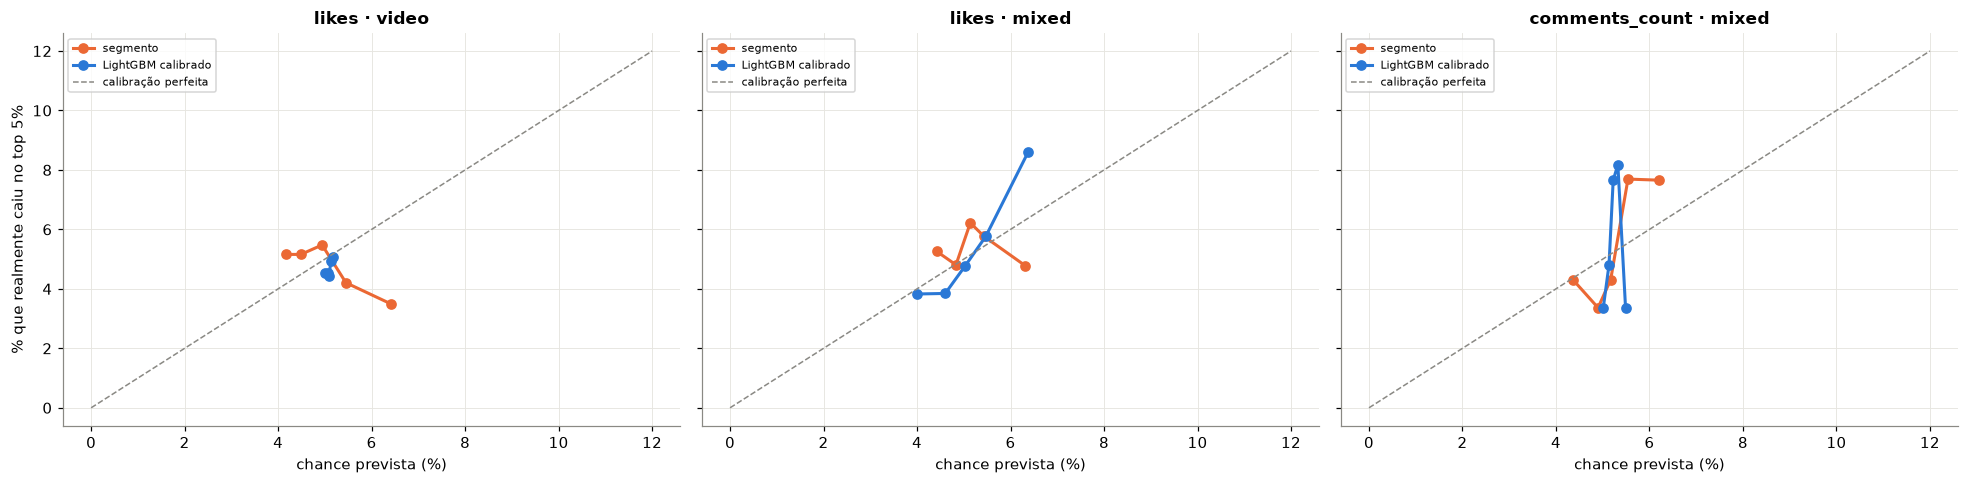

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5), sharey=True)
for ax, (metric, media) in zip(axes, [("likes", "video"), ("likes", "mixed"), ("comments_count", "mixed")]):
    _, preds = hp.evaluate(df, metric, media)
    for name, color in [("segmento (plataforma × categoria × idioma)", plots.ORANGE), ("LightGBM calibrado", plots.BLUE)]:
        cal = hp.calibration_table(preds["y"], preds[name])
        ax.plot(cal["previsto"], cal["observado"], "o-", color=color, linewidth=2, label=name.split(" (")[0])
    ax.plot([0, 12], [0, 12], color=plots.GRAY, linestyle="--", linewidth=1, label="calibração perfeita")
    ax.set_xlabel("chance prevista (%)"); ax.set_title(f"{metric} · {media}"); ax.legend(fontsize=7)
axes[0].set_ylabel("% que realmente caiu no top 5%")
fig.tight_layout(); plt.show()

**Leitura:** as previsões ficam espremidas perto de 5% (o modelo não tem informação para se afastar da base), e a taxa observada oscila em torno da diagonal sem acompanhá-la.
Uma ferramenta que prometesse "seu vídeo tem 15% de chance" estaria **inventando**.

## 3. Simulador: o mesmo post em cada formato

In [4]:
history = add_creator_history(df)
typical = {c: history[c].astype(str).mode()[0] for c in hp.CATEGORICAL} | {c: float(history[c].median()) for c in hp.NUMERIC}
scenarios = {
    "TikTok · beauty · espanhol": {"platform": "TikTok", "content_category": "beauty", "language": "Spanish"},
    "YouTube · tech · inglês": {"platform": "YouTube", "content_category": "tech", "language": "English"},
    "Bilibili · lifestyle · hindi": {"platform": "Bilibili", "content_category": "lifestyle", "language": "Hindi"},
}
planned = pd.DataFrame([typical | sc | {"content_type": t, "cenário": name}
                        for name, sc in scenarios.items() for t in sorted(df.content_type.unique())])
result = predictor.predict(planned)
result["cenário"] = planned["cenário"].values[result["post"]]
view = result.pivot_table(index=["cenário", "formato"], columns="métrica",
                          values=["chance top 5% (%)", "sinal do segmento (%)"]).round(1)
view

chance top 5% (%)                \
métrica                                 comments_count  likes  views   
cenário                      formato                                   
Bilibili · lifestyle · hindi image              5.5000 5.3000 5.1000   
                             mixed              5.3000 5.3000 5.1000   
                             text               5.3000 5.2000 5.1000   
                             video              5.0000 5.0000 5.0000   
TikTok · beauty · espanhol   image              5.5000 5.3000 5.1000   
                             mixed              5.3000 5.3000 5.1000   
                             text               5.3000 5.2000 5.1000   
                             video              5.0000 5.0000 5.0000   
YouTube · tech · inglês      image              5.5000 5.3000 5.1000   
                             mixed              5.3000 5.3000 5.1000   
                             text               5.3000 5.2000 5.1000   
                             video              5.0000 5.0000 5.0000   

                                     sinal do segmento (%)                
métrica                                     comments_count  likes  views  
cenário                      formato                                      
Bilibili · lifestyle · hindi image                  5.2000 4.4000 5.6000  
                             mixed                  5.7000 4.9000 5.5000  
                             text                   4.7000 5.3000 4.8000  
                             video                  6.8000 5.2000 5.2000  
TikTok · beauty · espanhol   image                  6.7000 5.5000 4.6000  
                             mixed                  5.5000 5.9000 5.0000  
                             text                   5.1000 5.0000 4.9000  
                             video                  5.1000 9.3000 4.8000  
YouTube · tech · inglês      image                  5.9000 4.7000 5.7000  
                             mixed                  5.7000 5.7000 5.9000  
                             text                   6.4000 5.3000 6.5000  
                             video                  4.7000 4.5000 5.5000

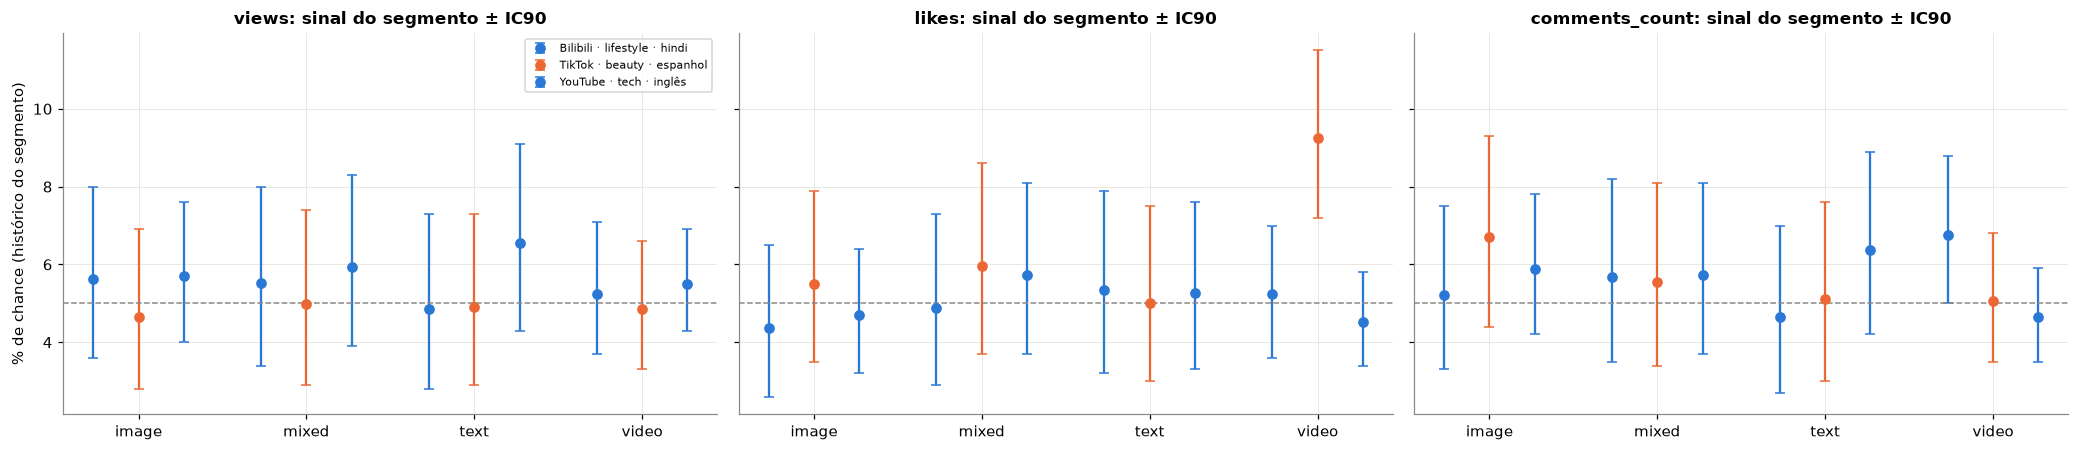

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(19, 4.2), sharey=True)
for ax, metric in zip(axes, hp.METRICS):
    sub = result[result["métrica"] == metric]
    for i, (name, g) in enumerate(sub.groupby("cenário")):
        x = np.arange(len(g)) + i * 0.27
        lows = [float(s.split("–")[0]) for s in g["segmento IC90 (%)"]]; highs = [float(s.split("–")[1]) for s in g["segmento IC90 (%)"]]
        ax.errorbar(x, g["sinal do segmento (%)"], yerr=[g["sinal do segmento (%)"] - lows, np.array(highs) - g["sinal do segmento (%)"]],
                    fmt="o", capsize=3, label=name)
    ax.axhline(5, color=plots.GRAY, linestyle="--", linewidth=1)
    ax.set_xticks(np.arange(4) + 0.27, sorted(df.content_type.unique())); ax.set_title(f"{metric}: sinal do segmento ± IC90")
axes[0].set_ylabel("% de chance (histórico do segmento)"); axes[0].legend(fontsize=7)
fig.tight_layout(); plt.show()

**Leitura:**
- **TikTok · beauty · espanhol, likes em vídeo:** o sinal do segmento sobe para ~**9%** (quase 2x a base), com intervalo que não cruza 5%. É o achado robusto do notebook 11 aparecendo na ferramenta.
- Nos outros cenários, os sinais ficam perto de 5%, com intervalos que incluem a base.
- **Chance oficial = taxa base** em todas as combinações, porque nenhum modelo passou na correção. O sinal do segmento é a **pista** para priorizar testes.

## 4. Como usar
```bash
.venv/bin/python solution/cli/predict_hit.py --platform TikTok --content_category beauty --language Spanish --hour 19
.venv/bin/python solution/cli/predict_hit.py --content_type video --platform YouTube --content_category tech --follower_count 50000
.venv/bin/python solution/cli/predict_hit.py --retrain      # após atualizar os dados
```
A saída traz 3 tabelas (formato × métrica): **chance oficial (%)**, **sinal do segmento (%)** e **intervalo de 90%** do sinal.

## 5. Conclusões
1. **Nenhum modelo** (segmento, logística, LightGBM) prevê a chance de top 5% melhor que a taxa base de forma confiável, em nenhum formato ou métrica.
2. A ferramenta é **honesta**: devolve ~5% e avisa. Com dados reais (ou com o efeito plantado, ver testes), ela adota sozinha o modelo que funcionar.
3. O **sinal do segmento** traz a única pista consistente: **TikTok · beauty · espanhol → ~9% de chance de top 5% em likes de vídeo**.